In [1]:
import pandas as pd

# Load the customer churn dataset
df = pd.read_csv("../data/customer_churn.csv")

# Display the first five rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset Information:")
df.info()

Dataset Shape: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    


In [3]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [4]:
# Count duplicate rows
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)


Number of duplicate rows: 0


In [5]:
# Check missing values in each column
missing_values = df.isnull().sum()

print(missing_values)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [6]:
# Check blank or whitespace-only values
for column in df.select_dtypes(include="object").columns:
    blank_count = df[column].str.strip().eq("").sum()

    if blank_count > 0:
        print(f"{column}: {blank_count} blank values")

TotalCharges: 11 blank values


C:\Users\Yash\AppData\Local\Temp\ipykernel_6044\1221259290.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in df.select_dtypes(include="object").columns:


In [7]:
# Convert TotalCharges to numeric values
# Blank or invalid values will become NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Check missing values after conversion
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

# Display the affected customer records
df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Missing TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [8]:
# Create a cleaned copy of the dataset
df_clean = df.copy()

# Remove records with missing TotalCharges
df_clean = df_clean.dropna(subset=["TotalCharges"]).copy()

# Verify the cleaning
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Remaining missing values:", df_clean.isnull().sum().sum())

Original dataset shape: (7043, 21)
Cleaned dataset shape: (7032, 21)
Remaining missing values: 0


In [9]:
# Count customers who stayed and left
churn_counts = df_clean["Churn"].value_counts()

print("Customer Churn Summary:")
print(churn_counts)

# Calculate churn rate
churn_rate = (df_clean["Churn"] == "Yes").mean() * 100

print(f"\nCustomer Churn Rate: {churn_rate:.2f}%")

Customer Churn Summary:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Customer Churn Rate: 26.58%


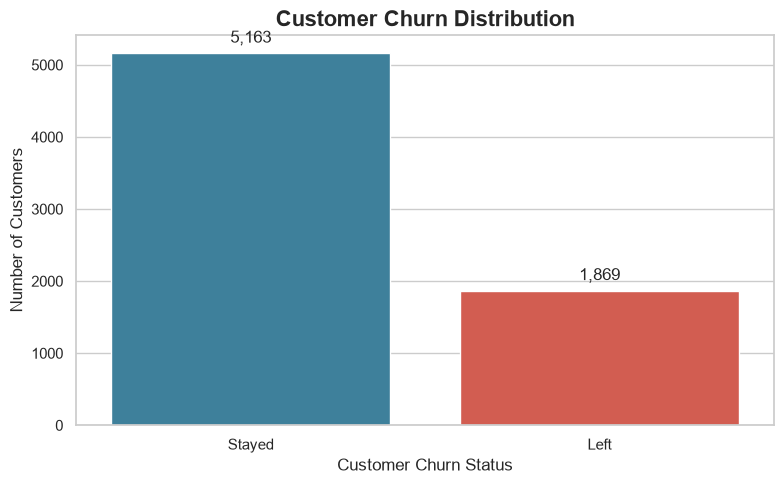

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean chart style
sns.set_theme(style="whitegrid")

# Create the chart
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df_clean,
    x="Churn",
    hue="Churn",
    order=["No", "Yes"],
    palette=["#2E86AB", "#E74C3C"],
    legend=False
)

# Add chart title and labels
plt.title("Customer Churn Distribution", fontsize=16, fontweight="bold")
plt.xlabel("Customer Churn Status", fontsize=12)
plt.ylabel("Number of Customers", fontsize=12)
plt.xticks([0, 1], ["Stayed", "Left"])

# Display the count above each bar
for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_height()):,}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.tight_layout()
plt.show()


In [11]:
# Calculate churn rate for each contract type
contract_churn = (
    df_clean.groupby("Contract", observed=True)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("Churn Rate by Contract Type:")
print(contract_churn.round(2))


Churn Rate by Contract Type:
Contract
Month-to-month    42.71
One year          11.28
Two year           2.85
Name: Churn, dtype: float64


In [12]:
# Calculate churn rate by customer tenure

tenure_churn = (
    df_clean.groupby("tenure")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

print("Churn Rate by Tenure:")
print(tenure_churn.head(12).round(2))

Churn Rate by Tenure:
tenure
1     61.99
2     51.68
3     47.00
4     47.16
5     48.12
6     36.36
7     38.93
8     34.15
9     38.66
10    38.79
11    31.31
12    32.48
Name: Churn, dtype: float64


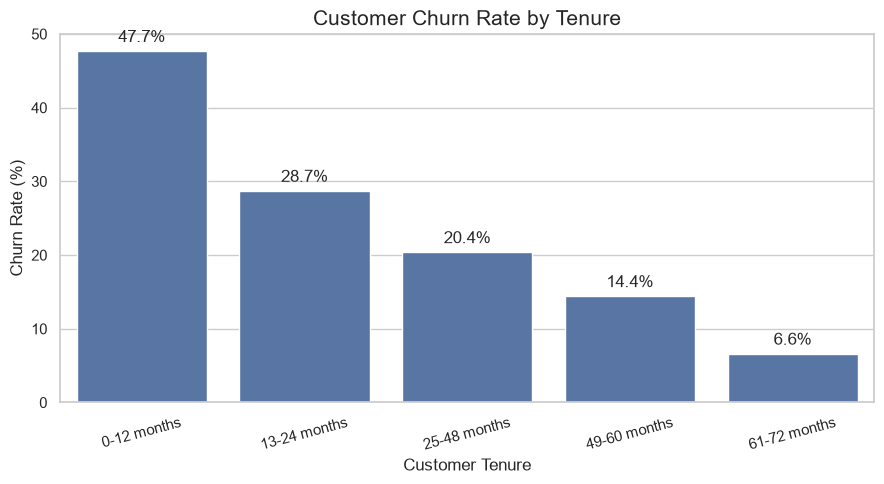

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group customers into tenure categories
df_clean["TenureGroup"] = pd.cut(
    df_clean["tenure"],
    bins=[-1, 12, 24, 48, 60, 72],
    labels=["0-12 months", "13-24 months",
            "25-48 months", "49-60 months",
            "61-72 months"]
)

# Calculate churn rate for each tenure group
tenure_group_churn = (
    df_clean.groupby("TenureGroup", observed=True)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

# Create chart
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=tenure_group_churn.index,
    y=tenure_group_churn.values
)

plt.title("Customer Churn Rate by Tenure", fontsize=15)
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=15)

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.tight_layout()
plt.show()

In [14]:
# Group customers by monthly charges

df_clean["MonthlyChargeGroup"] = pd.cut(
    df_clean["MonthlyCharges"],
    bins=[0, 35, 70, 100, float("inf")],
    labels=["Low", "Medium", "High", "Very High"],
    include_lowest=True
)

# Calculate churn rate for each group
charge_churn = (
    df_clean.groupby("MonthlyChargeGroup", observed=True)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

print("Churn Rate by Monthly Charges:")
print(charge_churn.round(2))

Churn Rate by Monthly Charges:
MonthlyChargeGroup
Low          10.93
Medium       23.98
High         37.85
Very High    28.05
Name: Churn, dtype: float64


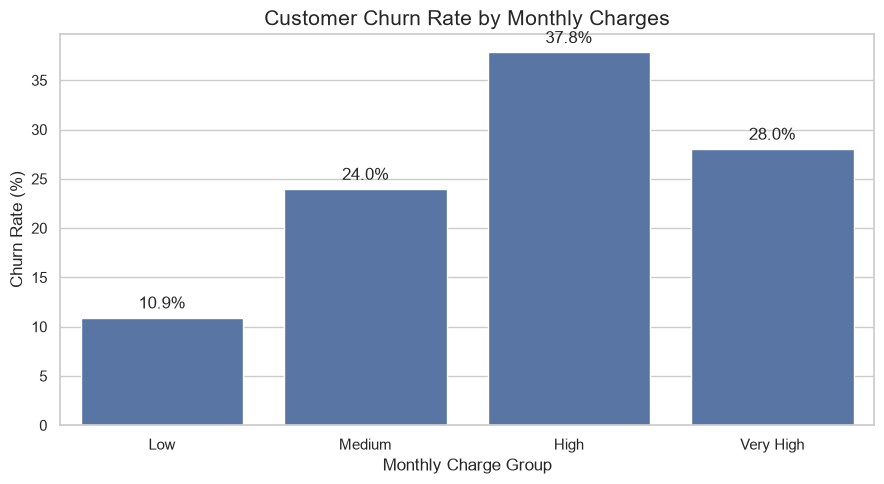

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=charge_churn.index,
    y=charge_churn.values
)

plt.title("Customer Churn Rate by Monthly Charges", fontsize=15)
plt.xlabel("Monthly Charge Group")
plt.ylabel("Churn Rate (%)")

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.tight_layout()
plt.show()

In [16]:
# Calculate churn rate by payment method

payment_churn = (
    df_clean.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("Churn Rate by Payment Method:")
print(payment_churn.round(2))

Churn Rate by Payment Method:
PaymentMethod
Electronic check             45.29
Mailed check                 19.20
Bank transfer (automatic)    16.73
Credit card (automatic)      15.25
Name: Churn, dtype: float64


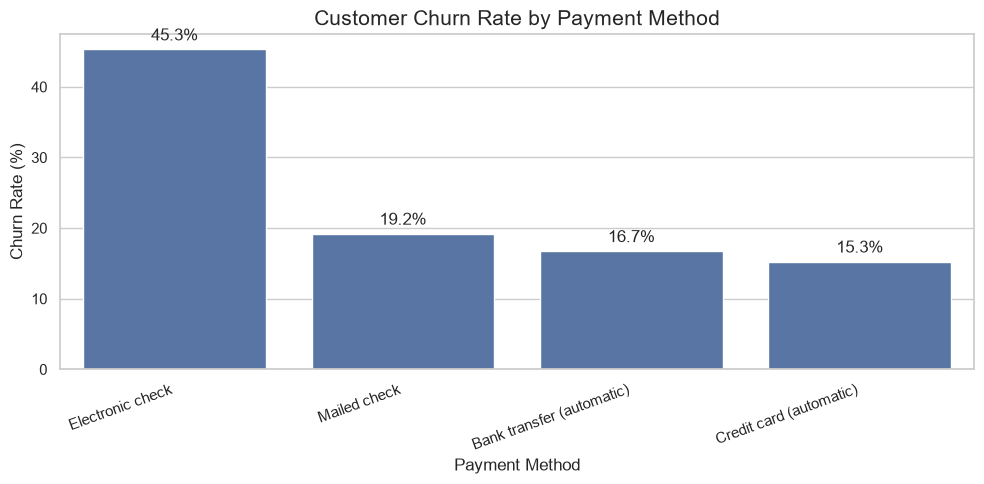

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=payment_churn.index,
    y=payment_churn.values
)

plt.title("Customer Churn Rate by Payment Method", fontsize=15)
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20, ha="right")

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.tight_layout()
plt.show()

In [18]:
# Calculate churn rate by internet service

internet_churn = (
    df_clean.groupby("InternetService")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("Churn Rate by Internet Service:")
print(internet_churn.round(2))

Churn Rate by Internet Service:
InternetService
Fiber optic    41.89
DSL            19.00
No              7.43
Name: Churn, dtype: float64


In [19]:
# Create a reusable function to calculate churn rates

def calculate_churn_rate(column):
    return (
        df_clean.groupby(column)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .round(2)
        .sort_values(ascending=False)
    )


# Calculate churn rates for important categories

contract_summary = calculate_churn_rate("Contract")
payment_summary = calculate_churn_rate("PaymentMethod")
internet_summary = calculate_churn_rate("InternetService")
tenure_summary = calculate_churn_rate("TenureGroup")
charge_summary = calculate_churn_rate("MonthlyChargeGroup")


print("CHURN BY CONTRACT")
print(contract_summary)

print("\nCHURN BY PAYMENT METHOD")
print(payment_summary)

print("\nCHURN BY INTERNET SERVICE")
print(internet_summary)

print("\nCHURN BY TENURE GROUP")
print(tenure_summary)

print("\nCHURN BY MONTHLY CHARGE GROUP")
print(charge_summary)

CHURN BY CONTRACT
Contract
Month-to-month    42.71
One year          11.28
Two year           2.85
Name: Churn, dtype: float64

CHURN BY PAYMENT METHOD
PaymentMethod
Electronic check             45.29
Mailed check                 19.20
Bank transfer (automatic)    16.73
Credit card (automatic)      15.25
Name: Churn, dtype: float64

CHURN BY INTERNET SERVICE
InternetService
Fiber optic    41.89
DSL            19.00
No              7.43
Name: Churn, dtype: float64

CHURN BY TENURE GROUP
TenureGroup
0-12 months     47.68
13-24 months    28.71
25-48 months    20.39
49-60 months    14.42
61-72 months     6.61
Name: Churn, dtype: float64

CHURN BY MONTHLY CHARGE GROUP
MonthlyChargeGroup
High         37.85
Very High    28.05
Medium       23.98
Low          10.93
Name: Churn, dtype: float64
